# SiN Photonic-Crystal Nanocavities II — The L3 Cavity

The L3 cavity, three missing holes in a line of a triangular photonic crystal slab, is the
workhorse of the Noda review. In silicon, shifting the two holes at the cavity ends outward
turns a Q of ≈ 5×10³ into 4.5×10⁴ (Akahane et al. 2003, measured), and optimizing three
pairs of end holes gives Q ≈ 1.6×10⁶ in simulation (Minkov & Savona 2014). The shifts make
the field envelope gentler, which removes the in-plane momentum components that fall inside
the light cone and radiate out of the slab.

This notebook builds the same cavity in the suspended 200 nm SiN membrane of notebook 01
(n = 2.0, r/a = 0.30) and asks how much of that improvement survives at n = 2.0:

1. the method (3D ring-down, Q, V and Purcell factor);
2. plain L3 and end-hole shifts in 3D FDTD;
3. a fast guided-mode-expansion (GME) screen of three shifts, checked against the
   silicon literature and the FDTD;
4. the final design at 637 nm: field, Q, V, F;
5. fabrication tolerance (±5 nm hole radius and membrane thickness).

**Model:** 3D Meep, bulk SiN n = 2.0 and air, non-dispersive and lossless (see notebook 01 and
`src/pic_toolkit/meep_sim/phc_cavity.py`). GME: `legume` (guided-mode expansion), separate conda
env `legume`.

**Kernel:** `mp` conda env, run from `sin_cavity/notebooks/`. All 3D runs come from
`scripts/run_l3.py` (12 MPI ranks) and are cached in `data/l3/`; the GME runs from
`scripts/gme_l3_scan.py` and `scripts/gme_validation.py`. **Do not use "Run All."**

## 0. Setup

In [1]:
# Imports, style, cached runs.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle

from pic_toolkit import style
from pic_toolkit.meep_sim import phc_cavity as pc

style.apply_style()
DATA = Path.cwd().parent / "data"
L3 = DATA / "l3"


def load(tag):
    # One cached ring-down: geometry, the Harminv mode list and the chosen mode's f, Q, V, F.
    return dict(np.load(L3 / f"{tag}.npz"))


def summary(o):
    return f"lambda {1e3 / o['f']:.1f} nm, Q {o['Q']:.3g}, V {o['V']:.2f} (lambda/n)^3, F {o['purcell']:.0f}"

## 1. Method: ring-down, Q, V and Purcell factor

Each 3D run follows the same steps (`pc.run_cavity`):

- **Cell.** The hole lattice covers ±14a along the cavity and ±10 rows across it, running into
  a 0.5 µm PML on every side; 0.6 µm of air above and below the membrane. At 642 nm the PML is 0.8 λ0 thick, the air
0.9 λ0, and the lattice spans ±5.8 λ0 along the cavity and ±3.6 λ0 across it. 1.0 µm of
air changes nothing (notebook 03); the in-plane extent was not varied, but the mode
reaches only 3–4 periods into the crystal (Section 4), far from the PML. Three mirror planes
  (x, y, z) reduce the computed volume eightfold and select the fundamental TE-like mode
  (Ey even about all three planes).
- **Excitation.** A Gaussian Ey pulse at the cavity centre. After the pulse, Harminv fits the
  ringing field at the centre with decaying sinusoids and returns the frequency f, the quality
  factor Q and the amplitude of every mode it finds.
- **Mode choice.** A broadband pulse excites several modes (higher-order cavity modes,
  band-edge modes of the finite crystal). The fundamental L3 mode is the one with the
  **highest Q** among those with ≥ 5 % of the strongest amplitude; neither the largest
  amplitude nor the lowest frequency picks it reliably. Every run's full mode list is kept.
- **Mode volume.** V = ∫ε|E|² dV / max(ε|E|²), from two field snapshots a quarter period apart
  (for one standing-wave mode their sum is the time-independent |E|² amplitude), in units of
  (λ/n)³ with n = 2.0. For the reported designs a second, narrowband pulse (Δf = 0.03 c/µm)
  centred on the found mode repeats the run, so that the field holds that mode only.
- **Purcell factor** F = 3/(4π²) Q/V, for an ideally placed and oriented dipole.

Resolution: 32 px/µm for scans, 64 px/µm (15.6 nm; 17 px per lattice constant, ≈ 10 px across a hole) for the final design; the
plain L3 changes by 2 % in Q between the two (below). Convergence and domain studies are
recorded in `docs/simulation_settings_record.md`.

In [2]:
# Mode list of the final design's broadband run: the fundamental L3 mode is the highest-Q entry.
o = load("l3_final_bb")
print(" f (c/um)   lambda (nm)        Q   |amp|")
for f, q, amp, err in np.real(o["modes"]):
    print(f"{f:9.4f} {1e3 / f:12.1f} {q:9.3g} {amp:7.2f}")
print("\nresolution check, plain L3 (a = 280 nm):")
for tag in ("l3_plain_res32", "l3_plain_res64"):
    p = load(tag)
    print(f"  {p['resolution']:.0f} px/um: lambda {1e3 / p['f']:.1f} nm, Q {p['Q']:.3g}")

 f (c/um)   lambda (nm)        Q   |amp|
   1.5580        641.8  3.03e+03   13.08
   1.6763        596.6       274    0.88
   1.5297        653.7       672    0.44

resolution check, plain L3 (a = 280 nm):
  32 px/um: lambda 662.2 nm, Q 506
  64 px/um: lambda 661.2 nm, Q 495


> **STOP -- the shift scan below is 16 runs of 15–40 min each at 32 px/µm
> (`scripts/run_l3.py`), cached in `data/l3/`.**

## 2. Plain L3 and end-hole shifts (3D FDTD, a = 280 nm)

First the textbook steps at a = 280 nm: the plain L3, the Akahane shift S1 of the first end
hole, a second shift S2 and the three Minkov–Savona shifts optimized for silicon
(0.327, 0.257, 0.116)a.

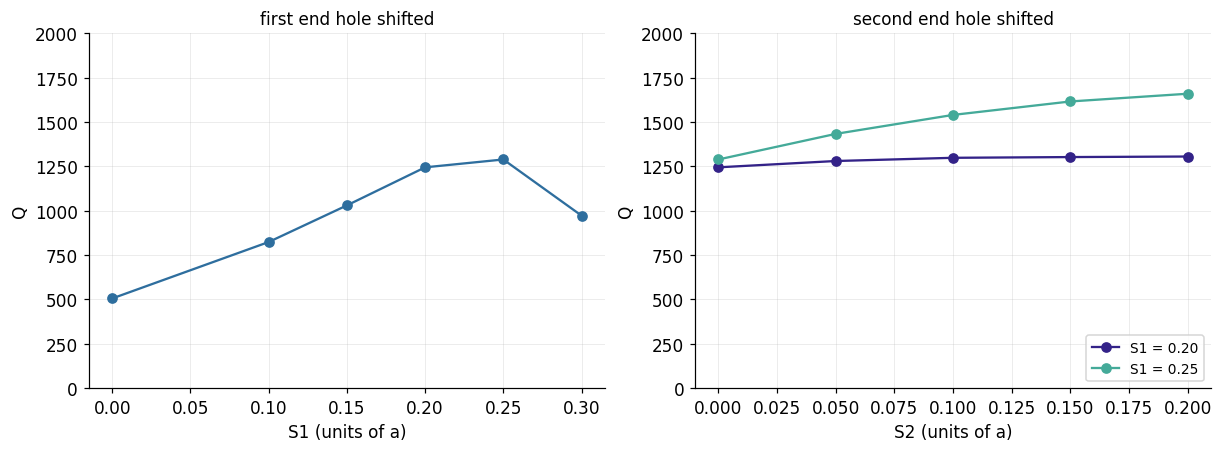

narrowband runs (single-mode V):
                           plain: lambda 662.2 nm, Q 506, V 0.78 (lambda/n)^3, F 49
                       S1 = 0.25: lambda 667.8 nm, Q 1.29e+03, V 0.97 (lambda/n)^3, F 101
            S1 = 0.25, S2 = 0.20: lambda 668.4 nm, Q 1.67e+03, V 1.04 (lambda/n)^3, F 122
    Minkov-Savona (Si-optimized): lambda 669.3 nm, Q 2.27e+03, V 1.13 (lambda/n)^3, F 153


In [3]:
# Q vs the first shift S1 (S2 = 0) and vs S2 for two values of S1.
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
s1 = [0.0, 0.10, 0.15, 0.20, 0.25, 0.30]
q1 = [load("l3v2_plain_nb")["Q"]] + [load(f"l3_s1_{s:.2f}_res32")["Q"] for s in s1[1:]]
ax0.plot(s1, q1, "o-", color=style.COLOR_STEEL)
ax0.set_xlabel("S1 (units of a)"); ax0.set_ylabel("Q"); ax0.set_ylim(0, 2000)
ax0.set_title("first end hole shifted", fontsize=11)
for c, s in zip(style.COLOR_CYCLE[::2], (0.20, 0.25)):
    s2 = [0.0, 0.05, 0.10, 0.15, 0.20]
    q2 = [load(f"l3_s1_{s:.2f}_res32")["Q"]] + [load(f"l3_s{s:.2f}_{t:.2f}_res32")["Q"] for t in s2[1:]]
    ax1.plot(s2, q2, "o-", color=c, label=f"S1 = {s:.2f}")
ax1.set_xlabel("S2 (units of a)"); ax1.set_ylabel("Q"); ax1.set_ylim(0, 2000)
ax1.set_title("second end hole shifted", fontsize=11)
ax1.legend(loc="lower right", fontsize=9)
fig.savefig(DATA / "fig_l3_shift_scan.png", dpi=150, bbox_inches="tight")
plt.show()

print("narrowband runs (single-mode V):")
for tag, name in (("l3v2_plain_nb", "plain"), ("l3v2_s25_nb", "S1 = 0.25"),
                  ("l3v2_s25_20_nb", "S1 = 0.25, S2 = 0.20"), ("l3v2_ms3_nb", "Minkov-Savona (Si-optimized)")):
    print(f"  {name:>30}: {summary(load(tag))}")

The plain SiN L3 has Q ≈ 500, two orders of magnitude below silicon's. The end-hole shift
still helps: Q peaks at S1 ≈ 0.25a (≈ 1.3×10³), a larger optimal shift than in silicon
(0.15a), because the weaker SiN lattice confines the mode over more periods and the envelope
has to be stretched further. S2 adds another 30 %, and the silicon-optimized three-hole
shifts give 2.3×10³ — a factor 4.5 over the plain cavity, compared with ≈ 160 in silicon (GME, Section 3).
The mode volume grows from 0.78 to 1.13 (λ/n)³ as the shifts stretch the mode.

> **STOP -- each GME evaluation takes ≈ 40 s; the two grids (336 + 256 designs) took ≈ 7 h
> (`scripts/gme_l3_scan.py`, `legume` env), cached in `data/l3/gme_scan*.npz`.**

## 3. Screening three shifts with guided-mode expansion

A 3D FDTD run per design is too slow for a three-parameter search. Guided-mode expansion
(GME, `legume`) expands the cavity field in the guided modes of the unpatterned slab and
computes the radiative loss into the light cone by perturbation theory, on a periodic supercell
of 16 × 10 lattice periods. It captures the out-of-plane radiation that limits these cavities
but not in-plane leakage through the finite crystal, so it is used to rank designs and the
final design is checked in 3D FDTD.

First, the GME model is checked against the silicon literature and against the FDTD runs of
Section 2.

In [4]:
# GME vs literature (Si, n = 3.46, d = 0.55a, r = 0.25a) and vs 3D FDTD (SiN, Section 2).
G = np.load(L3 / "gme_validation.npz")
print("Si L3:                         GME Q     literature")
for k, lit in (("si_plain", "~5e3 (Akahane 2003, meas.)"), ("si_s1", "4.5e4 (Akahane 2003, meas.)"),
               ("si_ms3", "1.6e6 (Minkov & Savona 2014, sim.)")):
    print(f"  {k:>10}: f {G[k + '_f']:.4f} c/a  {G[k + '_Q']:9.3g}   {lit}")
print("\nSiN L3, a = 280 nm:           GME                 3D FDTD")
for k, tag in (("sin_plain", "l3v2_plain_nb"), ("sin_s25", "l3v2_s25_nb"),
               ("sin_s25_20", "l3v2_s25_20_nb"), ("sin_ms3", "l3v2_ms3_nb")):
    o = load(tag)
    print(f"  {k:>10}: {280 / G[k + '_f']:.0f} nm, Q {G[k + '_Q']:7.3g}    {1e3 / o['f']:.0f} nm, Q {o['Q']:7.3g}")

Si L3:                         GME Q     literature
    si_plain: f 0.2610 c/a   7.42e+03   ~5e3 (Akahane 2003, meas.)
       si_s1: f 0.2591 c/a   4.03e+04   4.5e4 (Akahane 2003, meas.)
      si_ms3: f 0.2579 c/a   1.18e+06   1.6e6 (Minkov & Savona 2014, sim.)

SiN L3, a = 280 nm:           GME                 3D FDTD
   sin_plain: 659 nm, Q     598    662 nm, Q     506
     sin_s25: 665 nm, Q 1.36e+03    668 nm, Q 1.29e+03
  sin_s25_20: 665 nm, Q 1.99e+03    668 nm, Q 1.67e+03


     sin_ms3: 666 nm, Q 2.63e+03    669 nm, Q 2.27e+03


GME reproduces the silicon literature to within the spread one expects between methods
(the literature values are measurements or 3D FDTD of finite crystals), and for SiN it
agrees with the 3D FDTD to within ≈ 1 % in wavelength and 5–20 % in Q, slightly
overestimating Q because in-plane loss is missing. Its ranking of designs can be trusted.

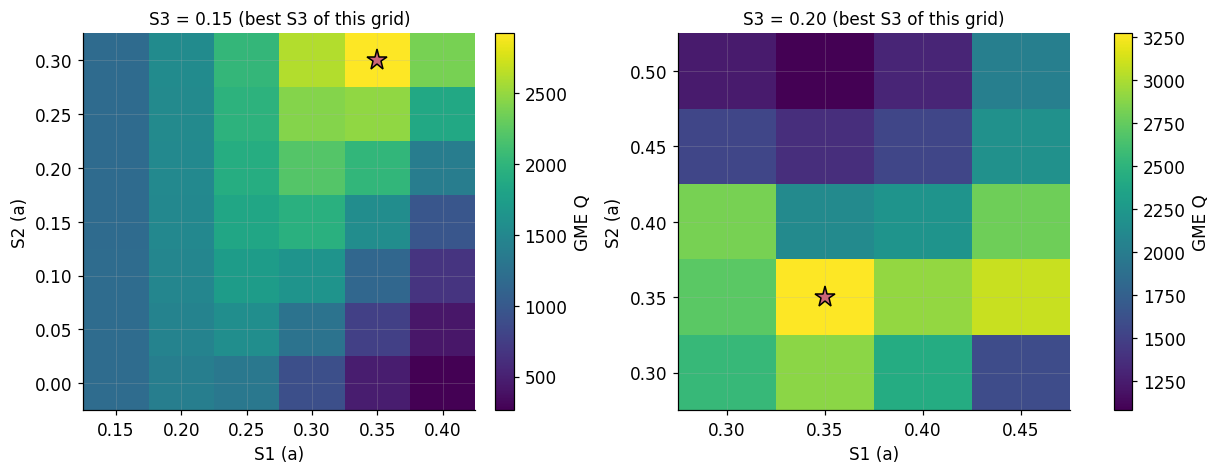

best GME design: S1 = 0.35, S2 = 0.35, S3 = 0.20, Q = 3.27e+03


In [5]:
# Q over (S1, S2) at the best S3 of each grid: first grid and the extension toward larger shifts.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
best = None
for ax, name in zip(axes, ("gme_scan", "gme_scan_ext")):
    S = np.load(L3 / f"{name}.npz")
    Q = S["Q"]
    i, j, k = np.unravel_index(np.nanargmax(Q), Q.shape)
    if best is None or Q[i, j, k] > best[3]:
        best = (S["S1"][i], S["S2"][j], S["S3"][k], Q[i, j, k])
    im = ax.pcolormesh(S["S1"], S["S2"], Q[:, :, k].T, shading="nearest", cmap=style.CMAP_DENSITY)
    ax.plot(S["S1"][i], S["S2"][j], "*", ms=14, color=style.COLOR_ROSE, mec="k")
    ax.set_xlabel("S1 (a)"); ax.set_ylabel("S2 (a)")
    ax.set_title(f"S3 = {S['S3'][k]:.2f} (best S3 of this grid)", fontsize=11)
    fig.colorbar(im, ax=ax, label="GME Q")
fig.savefig(DATA / "fig_l3_gme_scan.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"best GME design: S1 = {best[0]:.2f}, S2 = {best[1]:.2f}, S3 = {best[2]:.2f}, Q = {best[3]:.3g}")

The GME optimum sits at much larger shifts than in silicon, (S1, S2, S3) ≈ (0.35, 0.35, 0.20)a,
and the optimum is broad: most neighbouring designs reach 80–90 % of the best GME Q
(3.3×10³), against 1.2×10³ for S1 = 0.15 alone. With
the light cone covering so much of k-space at n = 2.0, reshaping the envelope by moving holes
cannot hide the mode from it; the SiN L3 saturates at Q ≈ 3×10³.

> **STOP -- the final design at 64 px/µm takes ≈ 3 h (broadband) + 3 h (narrowband) on 12 cores.**

## 4. Final L3 design at 637 nm

The best GME shifts, with the lattice constant scaled to a = 266.6 nm so that the mode moves
toward 637 nm (the membrane stays 200 nm, so the scaling is not exact).

a = 266.6 nm, r = 80.0 nm, shifts [0.35 0.35 0.2 ] a, 64 px/um: lambda 641.8 nm, Q 3.03e+03, V 1.13 (lambda/n)^3, F 204


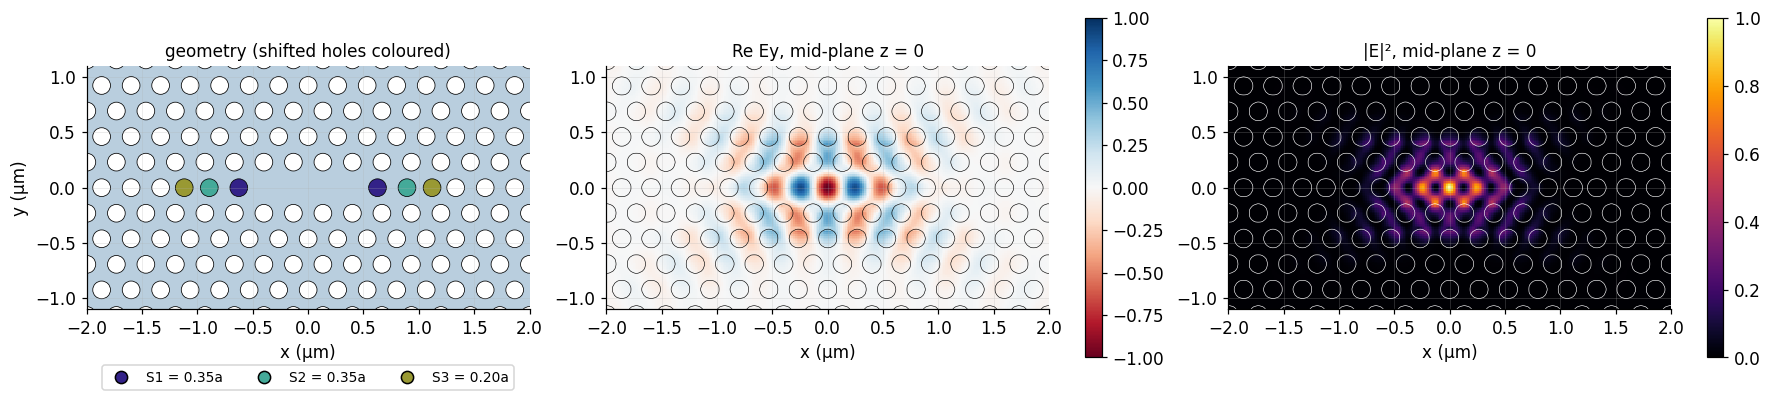

In [6]:
# Geometry near the cavity (holes from the cached run) and the field of the fundamental mode.
o = load("l3_final_nb")
a = float(o["a"])
print(f"a = {a * 1e3:.1f} nm, r = {o['r_a'] * a * 1e3:.1f} nm, shifts {o['shifts']} a, "
      f"{o['resolution']:.0f} px/um: {summary(o)}")
bx, by, bz = o["box"]
x = np.linspace(-bx / 2, bx / 2, o["e2_mid"].shape[0])
y = np.linspace(-by / 2, by / 2, o["e2_mid"].shape[1])
z = np.linspace(-bz / 2, bz / 2, o["e2_xz"].shape[1])
ey = o["ey_mid"] / np.abs(o["ey_mid"]).max()
e2 = o["e2_mid"] / o["e2_mid"].max()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
ax = axes[0]
row0 = np.abs(o["holes"][:, 1]) < 1e-6
ax_sorted = np.unique(np.round(np.abs(o["holes"][row0, 0]), 6))[:3]     # the S1, S2, S3 pairs
shifted = dict(zip(ax_sorted, (style.COLOR_CYCLE[0], style.COLOR_CYCLE[2], style.COLOR_CYCLE[4])))
for (hx, hy, hr), on_axis in zip(o["holes"], row0):
    fc = shifted.get(round(abs(hx), 6), "white") if on_axis else "white"
    ax.add_patch(Circle((hx, hy), hr, fc=fc, ec="k", lw=0.5))
ax.set_facecolor(style.COLOR_STEEL + "55")
ax.set_xlim(-2, 2); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)"); ax.set_title("geometry (shifted holes coloured)", fontsize=11)
for k, c in enumerate(shifted.values()):
    ax.plot([], [], "o", ms=8, mfc=c, mec="k", ls="none", label=f"S{k + 1} = {o['shifts'][k]:.2f}a")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
for ax, data, kw, lab in ((axes[1], ey, dict(cmap=style.CMAP_FIELD, vmin=-1, vmax=1), "Re Ey"),
                          (axes[2], e2, dict(cmap="inferno", vmin=0, vmax=1), "|E|²")):
    im = ax.pcolormesh(x, y, data.T, shading="auto", rasterized=True, **kw)
    ax.contour(x, y, o["eps_mid"].T, levels=[2.5], colors="k" if lab == "Re Ey" else "w", linewidths=0.4)
    ax.set_xlim(-2, 2); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
    ax.set_xlabel("x (µm)"); ax.set_title(f"{lab}, mid-plane z = 0", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.savefig(DATA / "fig_l3_final_field.png", dpi=150, bbox_inches="tight")
plt.show()

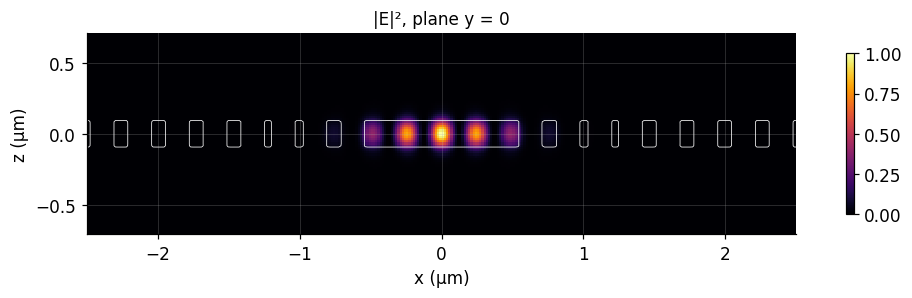

resolution check, final design: 32 px/um lambda 641.8 nm, Q 2.8e+03, V 1.19 (lambda/n)^3, F 179
                                64 px/um lambda 641.8 nm, Q 3.03e+03, V 1.13 (lambda/n)^3, F 204


In [7]:
# Cross-section through the cavity axis: |E|^2 in the x-z plane, membrane outline.
fig, ax = plt.subplots(figsize=(10, 2.6), layout="constrained")
im = ax.pcolormesh(x, z, (o["e2_xz"] / o["e2_xz"].max()).T, shading="auto", cmap="inferno", vmin=0, vmax=1, rasterized=True)
ax.contour(x, z, o["eps_xz"].T, levels=[2.5], colors="w", linewidths=0.5)
ax.set_xlim(-2.5, 2.5); ax.set_aspect("equal")
ax.set_xlabel("x (µm)"); ax.set_ylabel("z (µm)"); ax.set_title("|E|², plane y = 0", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(DATA / "fig_l3_final_xz.png", dpi=150, bbox_inches="tight")
plt.show()

nom32 = load("l3tol_nom")
print(f"resolution check, final design: 32 px/um {summary(nom32)}")
print(f"                                64 px/um {summary(o)}")

The fundamental L3 mode: Ey is even about both axes with its antinode in the cavity centre and
weaker lobes reaching 3–4 periods into the crystal, mostly along the diagonal rows. In the x–z plane
the field stays in the membrane with an evanescent tail in the air. At 64 px/µm the design
gives **λ = 641.8 nm, Q = 3.0×10³, V = 1.13 (λ/n)³, F ≈ 200**; 32 px/µm gives the same
wavelength and Q within 8 %, so the tolerance runs below use 32 px/µm and compare against
that nominal run. The wavelength is 5 nm above 637 nm; a 0.8 % smaller lattice constant
would centre it, which does not change Q or V at this level.

> **STOP -- five runs at 32 px/µm, ≈ 1 h each.**

## 5. Fabrication tolerance

Electron-beam lithography and etching typically change hole radii by a few nm, and LPCVD
membranes vary in thickness by a few nm across a wafer. Every hole radius is changed by ±5 nm
(r = 80 → 85 / 75 nm) and the membrane thickness by ±5 nm (195 / 205 nm), one at a time.

    nominal: lambda 641.8 nm, Q 2.8e+03, V 1.19 (lambda/n)^3, F 179   d lambda  +0.0 nm, Q/Q0 1.00
   r + 5 nm: lambda 633.0 nm, Q 1.79e+03, V 1.14 (lambda/n)^3, F 119   d lambda  -8.8 nm, Q/Q0 0.64
   r - 5 nm: lambda 651.3 nm, Q 4.61e+03, V 1.22 (lambda/n)^3, F 287   d lambda  +9.5 nm, Q/Q0 1.65
 t = 205 nm: lambda 644.6 nm, Q 2.92e+03, V 1.18 (lambda/n)^3, F 188   d lambda  +2.8 nm, Q/Q0 1.04
 t = 195 nm: lambda 639.1 nm, Q 2.69e+03, V 1.18 (lambda/n)^3, F 172   d lambda  -2.7 nm, Q/Q0 0.96


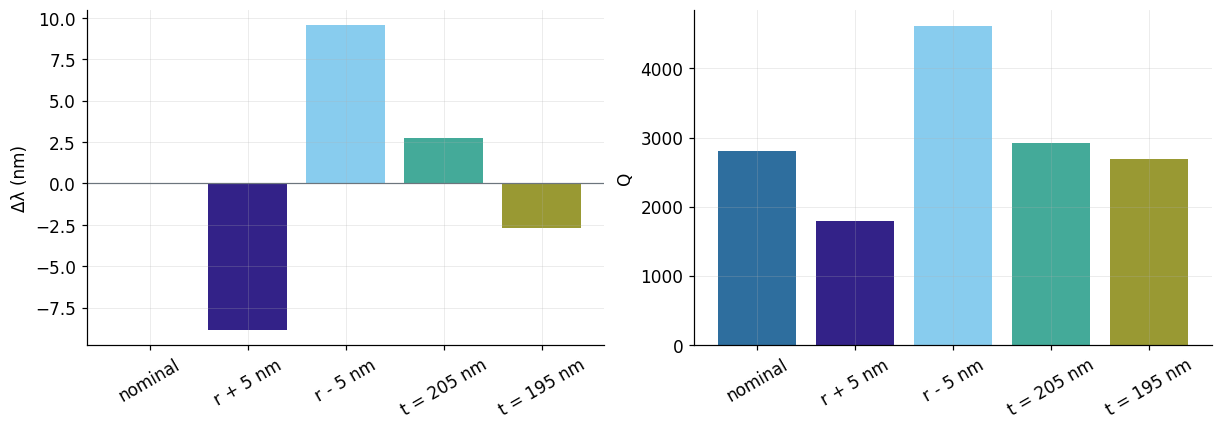

In [8]:
# Wavelength and Q of the final design under +-5 nm hole radius and thickness, 32 px/um.
runs = {"nominal": "l3tol_nom", "r + 5 nm": "l3tol_dr+5_nb", "r - 5 nm": "l3tol_dr-5",
        "t = 205 nm": "l3tol_t205", "t = 195 nm": "l3tol_t195"}
tol = {k: load(v) for k, v in runs.items()}
lam0, q0 = 1e3 / tol["nominal"]["f"], tol["nominal"]["Q"]
for k, o in tol.items():
    print(f"{k:>11}: {summary(o)}   d lambda {1e3 / o['f'] - lam0:+5.1f} nm, Q/Q0 {o['Q'] / q0:.2f}")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
names = list(tol)
cols = [style.COLOR_STEEL] + [style.COLOR_CYCLE[i] for i in (0, 1, 2, 4)]
ax0.bar(names, [1e3 / tol[k]["f"] - lam0 for k in names], color=cols)
ax0.axhline(0, color=style.COLOR_REFERENCE, lw=0.8)
ax0.set_ylabel("Δλ (nm)")
ax1.bar(names, [tol[k]["Q"] for k in names], color=cols)
ax1.set_ylabel("Q")
for ax in (ax0, ax1):
    ax.tick_params(axis="x", rotation=30)
fig.savefig(DATA / "fig_l3_tolerance.png", dpi=150, bbox_inches="tight")
plt.show()

A 5 nm change of every hole radius moves the resonance by ≈ 9 nm, about 40 linewidths
(λ/Q ≈ 0.2 nm); this is what post-fabrication tuning has to correct. A thickness change of
5 nm moves it by only ≈ 3 nm. Q stays between 1.8×10³ and 4.6×10³: smaller holes (more
dielectric, mode further from the light line) raise Q, larger holes lower it. The L3 is
forgiving because its Q is limited by the light cone everywhere in this parameter range.

## 6. Summary

| L3 in 200 nm SiN (n = 2.0), 3D FDTD | λ (nm) | Q | V (λ/n)³ | F |
|---|---|---|---|---|
| plain, a = 280 nm | 662 | 5.1×10² | 0.78 | 50 |
| S1 = 0.25a | 668 | 1.3×10³ | 0.97 | 100 |
| Minkov–Savona shifts (Si-optimized) | 669 | 2.3×10³ | 1.13 | 150 |
| **final: a = 266.6 nm, (0.35, 0.35, 0.20)a** | **642** | **3.0×10³** | **1.13** | **≈ 200** |
| measured SiN L3 / heterostructure (Barth 2007/2008 and others) | visible | 1.5–3.4×10³ | – | – |
| Si L3 (Akahane 2003 meas. / Minkov–Savona 2014 sim.) | 1.55 µm | 4.5×10⁴ / 1.6×10⁶ | ≈ 0.7–0.9 | – |

- End-hole shifts raise the SiN L3's Q six-fold, from 5×10² to 3.0×10³, at the price of a
  45 % larger mode volume. The optimal shifts are larger than in silicon and the optimum is
  flat; Q ≈ 3×10³ is close to the ceiling of this cavity type at n = 2.0, consistent with the
  measured SiN slab cavities.
- With ±5 nm in radius or thickness, the resonance moves by up to 9 nm and Q stays within
  1.8–4.6×10³.
- Notebook 03 shows the nanobeam in the same membrane, and compares the two.